# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox.

## Import the required packages

In [ ]:
from aitlas.datasets import RIT18Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import matplotlib.pyplot as plt
import numpy as np
import scipy.io

## Visualize images and masks

In [84]:
dataset_config = {
    "mat_file": "/home/dragik/data/FAIR_EO/RIT-18/rit18_data.mat",
    "mode" : "train"
}
dataset = RIT18Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 792


# Show images

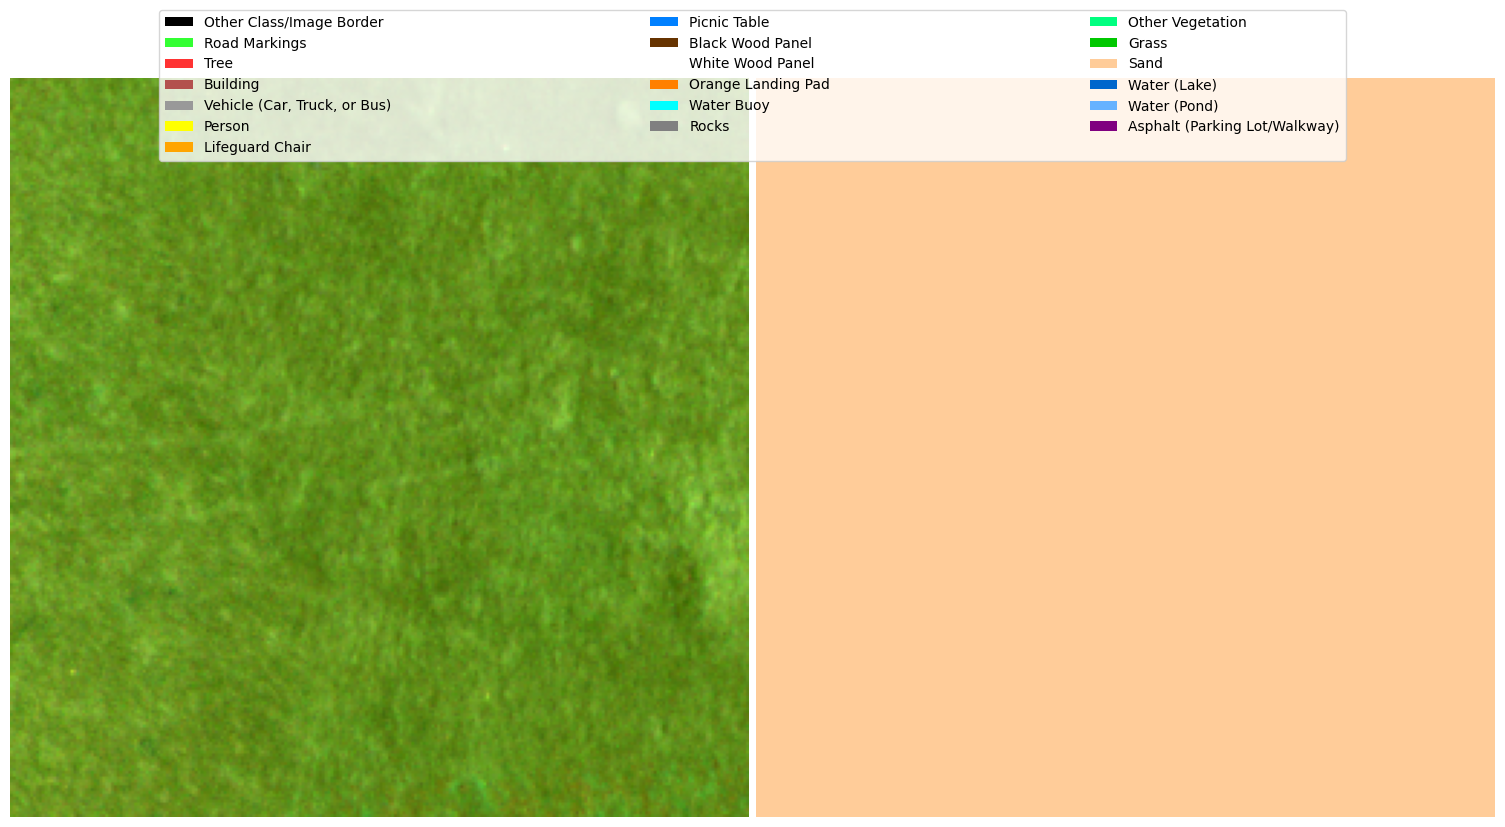

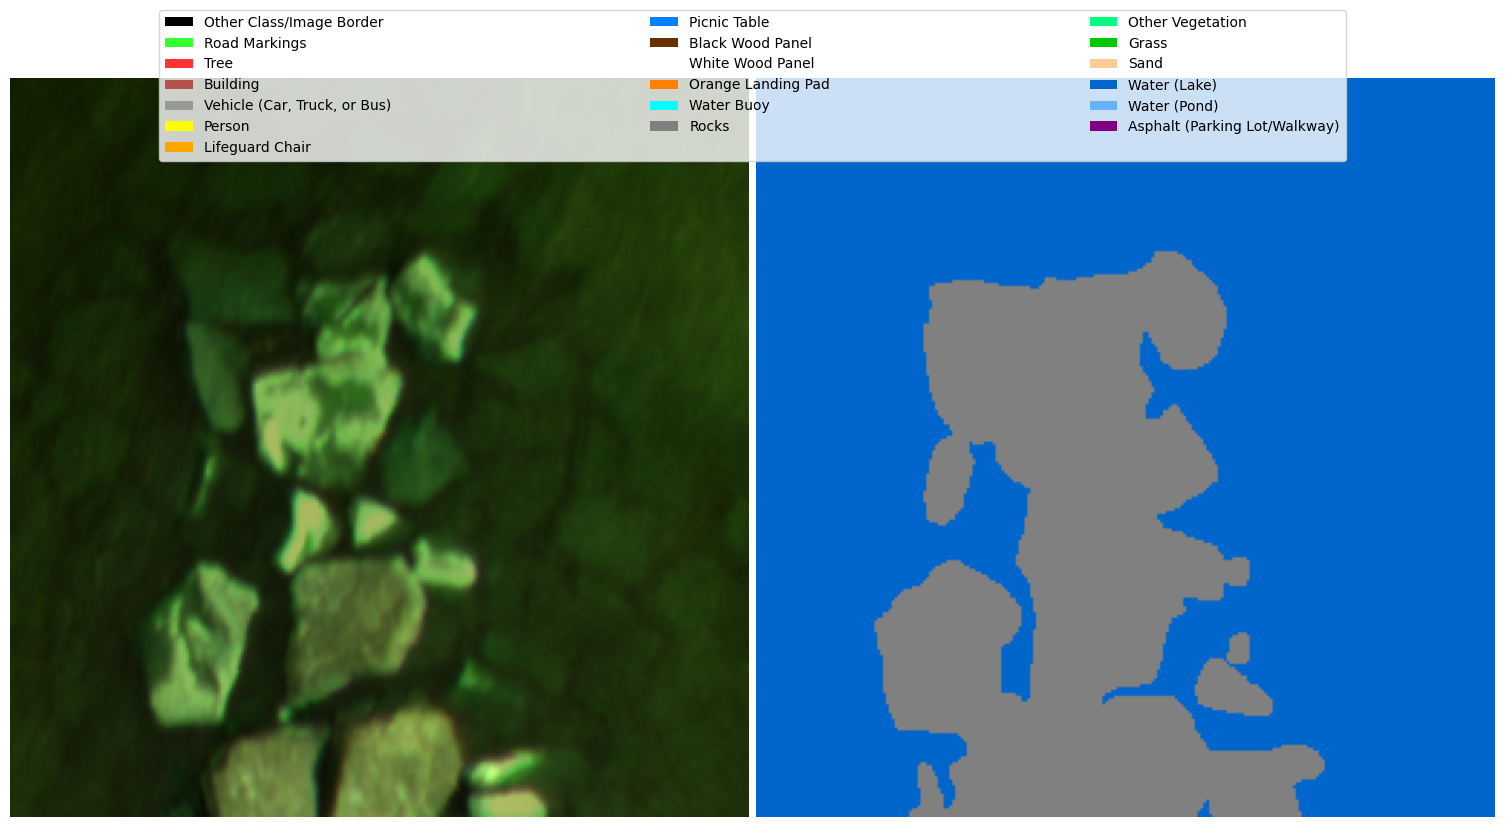

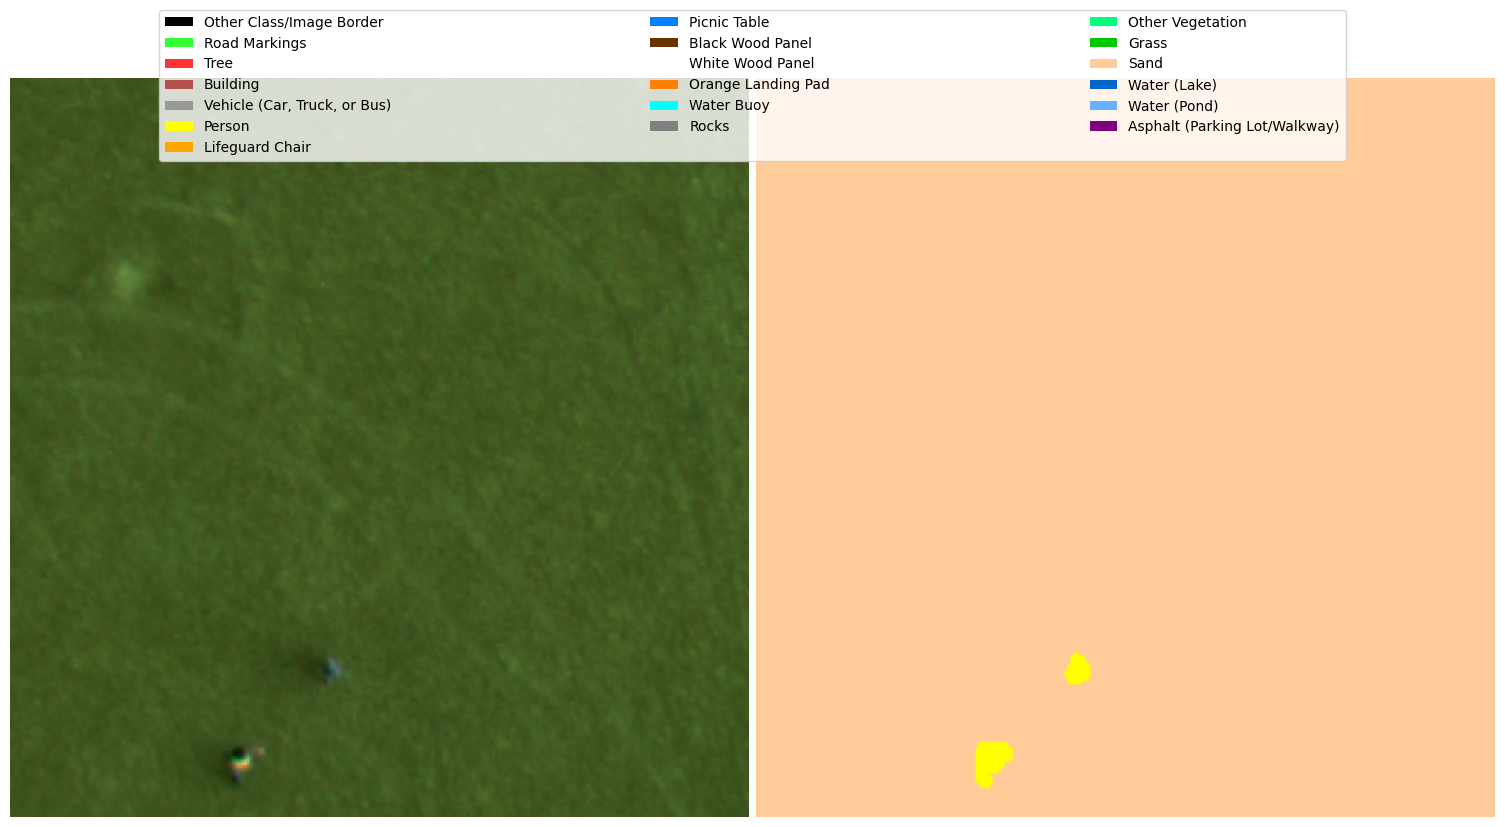

In [85]:
dataset.show_image(300)
dataset.show_image(150)
dataset.show_image(281);

In [7]:
dataset.data_distribution_table()

,Number of pixels
Other Class/Image Border,13782516
Road Markings,154048
Tree,6065240
Building,177727
"Vehicle (Car, Truck, or Bus)",43915
Person,1635
Lifeguard Chair,2763
Picnic Table,10677
Black Wood Panel,974
White Wood Panel,1170


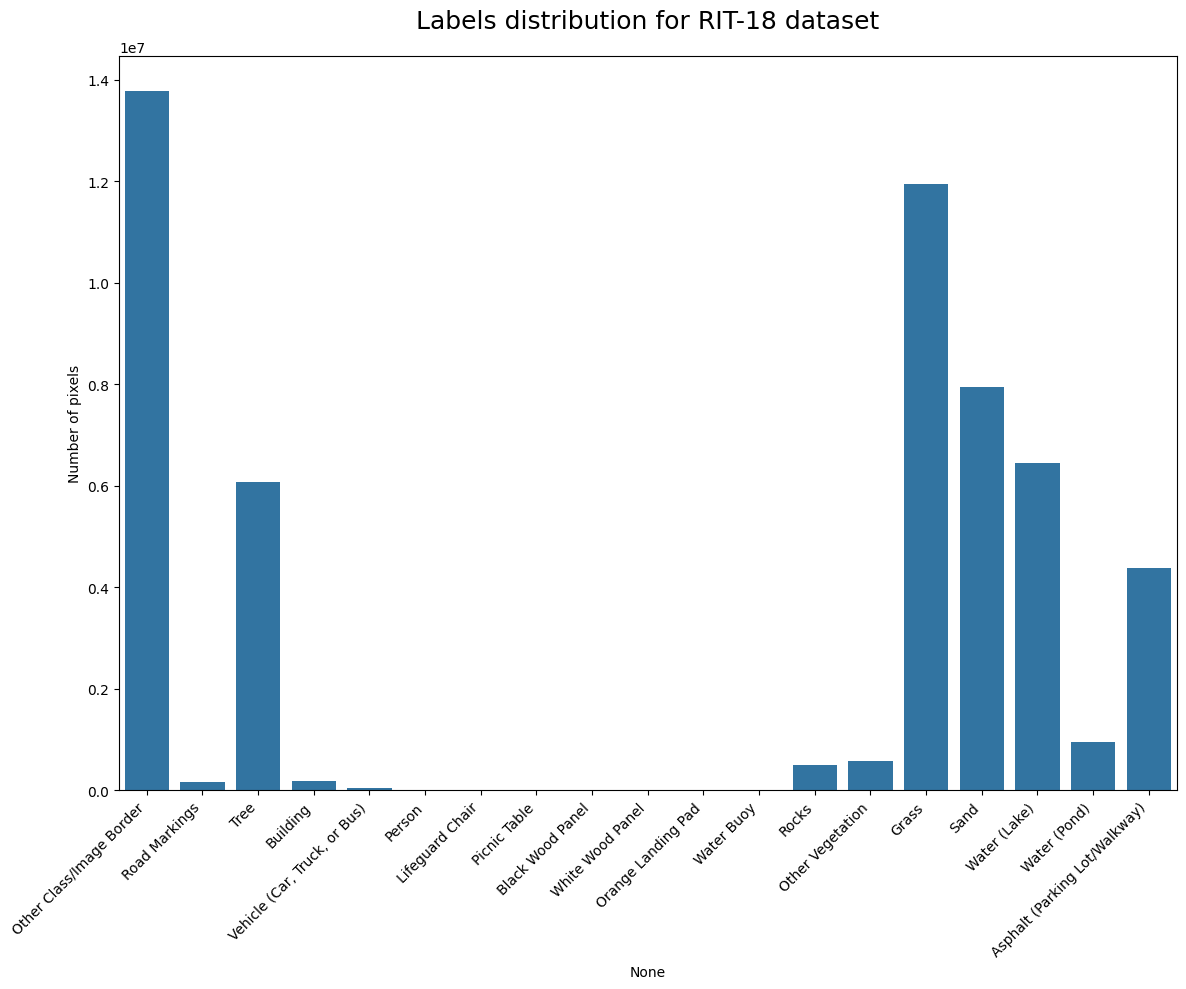

In [8]:
dataset.data_distribution_barchart();

## Load training data ##

In [13]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "mat_file": "/home/dragik/data/FAIR_EO/RIT-18/rit18_data.mat",
    "mode" : "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = RIT18Dataset(train_dataset_config)

len(train_dataset)

792

## Create the model ##

In [14]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/RIT18"
model_config = {
    "num_classes": 19, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [15]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-07-31 06:58:50,823 INFO Starting training.
training: 100%|██████████| 99/99 [06:49<00:00,  4.14s/it]
2025-07-31 07:05:40,295 INFO epoch: 1, time: 410, loss:  0.85039
testing on train set: 100%|██████████| 99/99 [06:54<00:00,  4.18s/it]
2025-07-31 07:12:36,356 INFO IOU:0.31166832472379186, IOU mean:0.12934305382845332, IOU per Class:[0.89599763 0.         0.23030125 0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.38483595 0.22211931 0.41820014 0.15292132
 0.15314242]
training: 100%|██████████| 99/99 [06:46<00:00,  4.11s/it]
2025-07-31 07:19:23,197 INFO epoch: 2, time: 407, loss:  0.77496
testing on train set: 100%|██████████| 99/99 [06:49<00:00,  4.14s/it]
2025-07-31 07:26:12,863 INFO IOU:0.4052249618007579, IOU mean:0.16488883485756958, IOU per Class:[0.89952608 0.         0.33322129 0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.40955649 0.30893927 0.50684391

0.26542469588193024

## Evaluate the model

In [16]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "mat_file": "/home/dragik/data/FAIR_EO/RIT-18/rit18_data.mat",
    "mode" : "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = RIT18Dataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/RIT18/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

918


2025-07-31 09:36:51,868 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RIT18/checkpoint.pth.tar
2025-07-31 09:36:52,332 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RIT18/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 230/230 [07:59<00:00,  2.09s/it]


[{'IOU': 0.25043946868522393,
  'IOU mean': 0.10989339518390875,
  'IOU per Class': array([0.95851722, 0.        , 0.00403324, 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.12310898,
         0.02931797, 0.46171985, 0.38939718, 0.12188006])}]

## Predictions

2025-07-31 12:53:21,373 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RIT18/checkpoint.pth.tar
2025-07-31 12:53:21,763 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RIT18/checkpoint.pth.tar at epoch 11


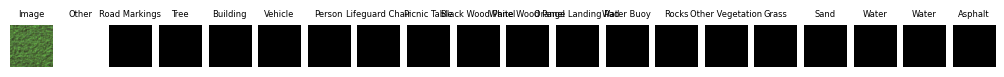

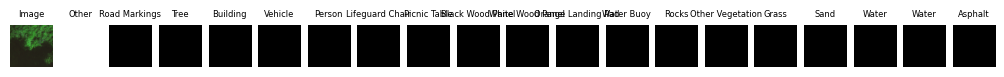

In [86]:
model_path = "/home/dragik/data/FAIR_EO/experiments/RIT18/checkpoint.pth.tar"
labels = ["Other", "Road Markings", "Tree", "Building", "Vehicle", "Person", "Lifeguard Chair", 
          "Picnic Table", "Black Wood Panel", "White Wood Panel", "Orange Landing Pad", "Water Buoy", 
          "Rocks", "Other Vegetation", "Grass", "Sand", "Water", "Water", "Asphalt"]
IMG_H, IMG_W = 256, 256
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 5})
mat = scipy.io.loadmat("/home/dragik/data/FAIR_EO/RIT-18/rit18_data.mat")
scene = mat['test_data']
height, width = scene.shape[1 :]
data = []
stride = IMG_H

for y in range(0, height - IMG_H + 1, stride):
    for x in range(0, width - IMG_W + 1, stride):
        if y + IMG_H <= height and x + IMG_W <= width:
            data.append((x,y))

x,y = data[1000]
image = scene[:3, y:y+IMG_H, x:x+IMG_W]
image = np.transpose(image, (1, 2, 0))/10000
fig = model.predict_masks(image, labels, transform)

x,y = data[1100]
image = scene[:3, y:y+IMG_H, x:x+IMG_W]
image = np.transpose(image, (1, 2, 0))/10000
fig = model.predict_masks(image, labels, transform)